# 01 · Exploratory data analysis

**Question:** is there anything in a stock's own price history (plus market context) that predicts its next-day return — and what does the data imply for how we should model it?

Each section ends with the modelling decision it motivates. The same analysis is available interactively on the app's *Explore* page for any ticker.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from stocksense import pipeline
from stocksense.config import load_config
from stocksense.features import feature_columns, labeled, FEATURE_DESCRIPTIONS

BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#898781'
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#c3c2b7', 'font.size': 10})

TICKER, YEARS = 'AAPL', 5
ds = pipeline.load_dataset(load_config(), TICKER, YEARS)
prices, frame = ds.prices, ds.frame
ret = np.log(prices['Close']).diff().dropna()
print(f'{TICKER}: {len(prices)} trading days, {prices.index[0]:%Y-%m-%d} → {prices.index[-1]:%Y-%m-%d}')
prices.tail()

AAPL: 1254 trading days, 2021-11-02 → 2026-10-30


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-26,343.920013,347.089996,341.029999,343.910004,42743600.0
2026-10-27,343.170013,347.779999,342.390015,347.100006,39984400.0
2026-10-28,346.920013,347.179993,343.519989,343.829987,35714300.0
2026-10-29,348.000000,351.429993,347.299988,348.910004,42582100.0
2026-10-30,346.720001,349.190002,334.350006,344.630005,67797500.0


## 1 · Price vs returns

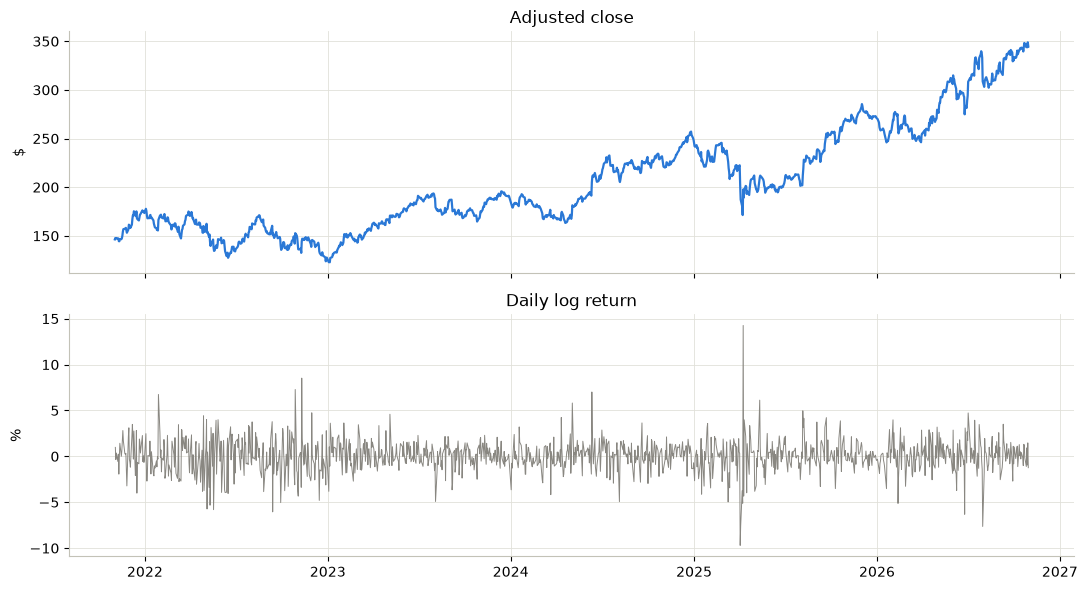

In [2]:
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
a.plot(prices['Close'], color=BLUE, lw=1.6); a.set_title('Adjusted close'); a.set_ylabel('$')
b.plot(ret * 100, color=GREY, lw=0.7); b.set_title('Daily log return'); b.set_ylabel('%')
plt.tight_layout()

The price trends; returns hover around zero with bursts of large moves. Prices and returns behave very differently, which the next two sections quantify.

## 2 · Stationarity (Augmented Dickey–Fuller)

In [3]:
rows = []
for name, s in [('Close', prices['Close']), ('Log price', np.log(prices['Close'])), ('Log return', ret)]:
    stat, p, *_ = adfuller(s.dropna(), autolag='AIC')
    rows.append({'series': name, 'ADF stat': round(stat, 3), 'p-value': round(p, 4),
                 'stationary (5%)': p < 0.05})
pd.DataFrame(rows).set_index('series')

,ADF stat,p-value,stationary (5%)
series,,,
Close,-0.094,0.9500,False
Log price,-0.597,0.8717,False
Log return,-34.496,0.0000,True


**Decision:** the price level has a unit root; log returns are stationary. All models predict the **next-day log return** and convert back to a price, instead of regressing on raw prices (the original project's approach, which mostly learns to copy yesterday's price).

## 3 · Distribution of returns

ann. mean +17.2% | ann. vol 27.9% | skew +0.17 | excess kurtosis 5.73 | JB p = 0.0e+00
|z| > 3 on 1.20% of days vs 0.27% under normality


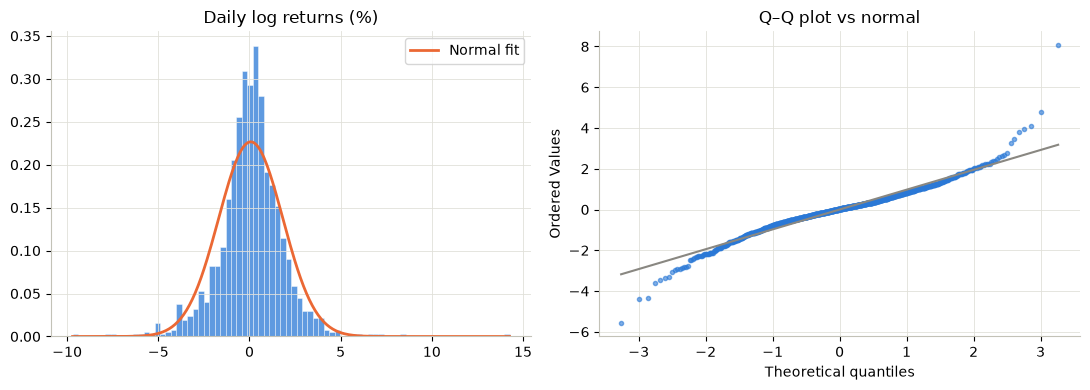

In [4]:
skew, kurt = stats.skew(ret), stats.kurtosis(ret)
z = (ret - ret.mean()) / ret.std()
print(f'ann. mean {ret.mean()*252:+.1%} | ann. vol {ret.std()*np.sqrt(252):.1%} | '
      f'skew {skew:+.2f} | excess kurtosis {kurt:.2f} | JB p = {stats.jarque_bera(ret).pvalue:.1e}')
print(f'|z| > 3 on {(z.abs() > 3).mean():.2%} of days vs {2*stats.norm.sf(3):.2%} under normality')

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.hist(ret * 100, bins=80, density=True, color=BLUE, alpha=0.75, edgecolor='white', linewidth=0.4)
xs = np.linspace(ret.min() * 100, ret.max() * 100, 300)
a.plot(xs, stats.norm.pdf(xs, ret.mean() * 100, ret.std() * 100), color=ORANGE, lw=2, label='Normal fit')
a.set_title('Daily log returns (%)'); a.legend()
stats.probplot(z, dist='norm', plot=b); b.get_lines()[0].set(color=BLUE, markersize=3, alpha=0.6)
b.get_lines()[1].set(color=GREY); b.set_title('Q–Q plot vs normal')
plt.tight_layout()

**Decision:** returns are fat-tailed (excess kurtosis ≫ 0), so forecast intervals use **empirical (split-conformal) residual quantiles** instead of a Gaussian ±1.96σ.

## 4 · Autocorrelation: direction vs magnitude

,Ljung–Box p (10 lags)
returns,4.200267e-01
|returns|,7.754052e-33


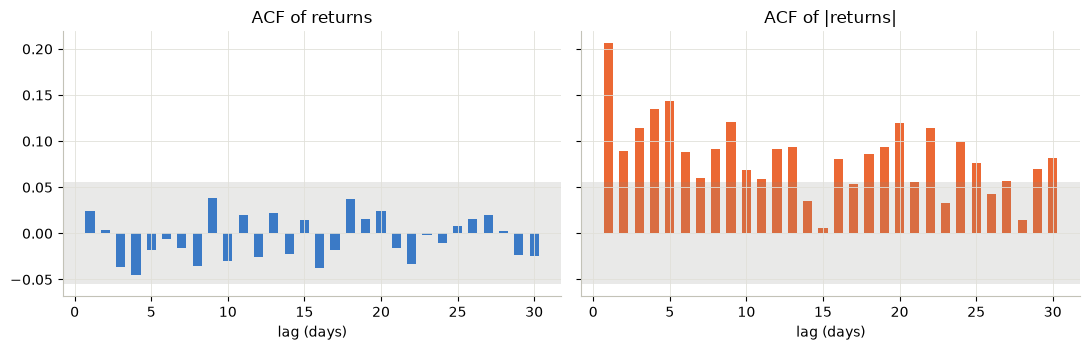

In [5]:
conf = 1.96 / np.sqrt(len(ret))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, series, title, color in [(axes[0], ret, 'ACF of returns', BLUE),
                                 (axes[1], ret.abs(), 'ACF of |returns|', ORANGE)]:
    v = acf(series, nlags=30, fft=True)[1:]
    ax.bar(range(1, 31), v, color=color, width=0.6)
    ax.axhspan(-conf, conf, color=GREY, alpha=0.18, lw=0); ax.set_title(title); ax.set_xlabel('lag (days)')
plt.tight_layout()
pd.DataFrame({'Ljung–Box p (10 lags)': [acorr_ljungbox(ret, lags=[10])['lb_pvalue'].iloc[0],
                                         acorr_ljungbox(ret.abs(), lags=[10])['lb_pvalue'].iloc[0]]},
             index=['returns', '|returns|'])

Returns are close to white noise, while absolute returns are strongly persistent (**volatility clustering**). **Decision:** include realised-volatility and VIX features, and expect next-day *direction* to be hard to beat — hence the random-walk benchmark and the Diebold–Mariano test in the Model Lab.

## 5 · Volatility regimes and market context

corr(21d vol, VIX) = 0.55
beta vs SPY = 1.16, correlation = 0.71


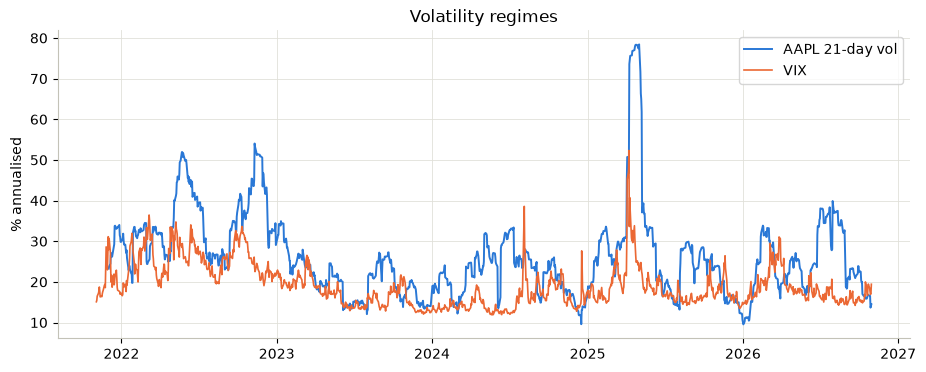

In [6]:
vol = ret.rolling(21).std() * np.sqrt(252) * 100
fig, ax = plt.subplots()
ax.plot(vol, color=BLUE, lw=1.4, label=f'{TICKER} 21-day vol')
if ds.market is not None and 'vix_close' in ds.market:
    vix = ds.market['vix_close'].reindex(vol.index).ffill()
    ax.plot(vix, color=ORANGE, lw=1.2, label='VIX')
    print(f'corr(21d vol, VIX) = {vol.corr(vix):.2f}')
ax.set_ylabel('% annualised'); ax.legend(); ax.set_title('Volatility regimes')
if ds.market is not None and 'mkt_close' in ds.market:
    m = np.log(ds.market['mkt_close']).diff().reindex(ret.index)
    beta = ret.cov(m) / m.var()
    print(f'beta vs SPY = {beta:.2f}, correlation = {ret.corr(m):.2f}')

Both series share units (% annualised volatility), so one axis is honest here. The stock's volatility tracks the VIX and its returns co-move with the market (beta ≈ 1). **Decision:** add SPY return/momentum/volatility and VIX level/change as context features.

## 6 · Feature signal (information coefficient)

max |IC| = 0.044 (macd)


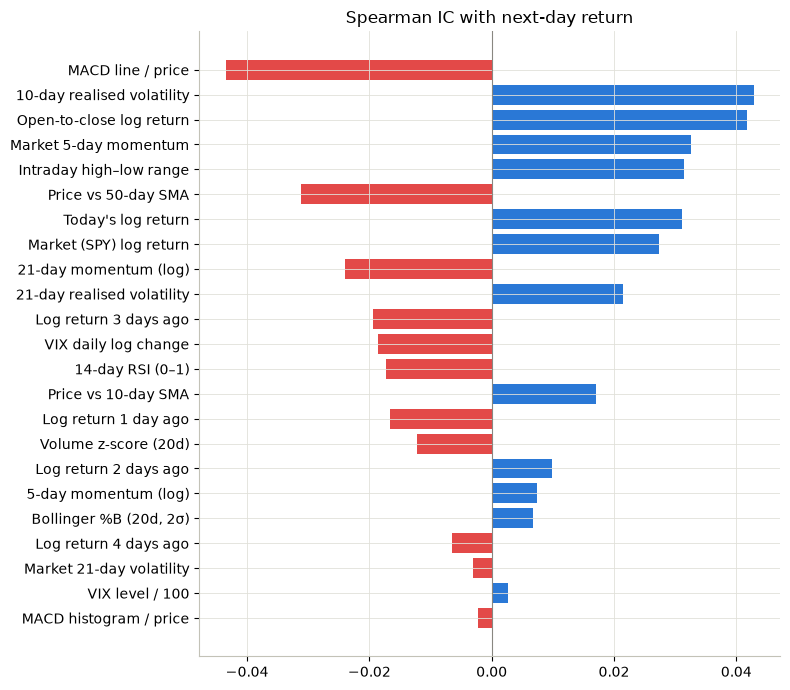

In [7]:
data = labeled(frame)
feats = feature_columns(data)
ic = data[feats].corrwith(data['target'], method='spearman').sort_values(key=np.abs)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([FEATURE_DESCRIPTIONS.get(f, f) for f in ic.index], ic.values,
        color=[BLUE if v >= 0 else '#e34948' for v in ic.values])
ax.axvline(0, color=GREY, lw=0.8); ax.set_title('Spearman IC with next-day return')
plt.tight_layout()
print(f'max |IC| = {ic.abs().max():.3f} ({ic.abs().idxmax()})')

Every individual feature is weakly related to tomorrow's return (|IC| of a few hundredths). **Decision:** combine features with regularised models (Ridge, shallow XGBoost with early stopping) and judge them only on walk-forward, out-of-sample performance.

## 7 · Summary → modelling choices

| Finding | Modelling consequence |
|---|---|
| Prices have a unit root; returns are stationary | Predict next-day **log return**, convert to price |
| Fat tails | **Conformal** intervals from empirical residuals |
| Returns ≈ white noise | **Random-walk benchmark** + Diebold–Mariano significance test |
| Volatility clusters, tracks VIX | Realised-vol, VIX and market features |
| Weak individual signals | Regularised models, walk-forward evaluation, no in-sample claims |

Next: run the models — `python -m scripts.train --ticker AAPL --track` or the app's *Model Lab*.